In [6]:
!pip install pandas matplotlib seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 10.9/10.9 MB 59.1 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 9.5/9.5 MB 76.6 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 62.9 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 12.7/12.7 MB 73.3 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 88.6 MB/s  0:00:00

   ----------------------------------------  0/10 [pyparsing]
   ----------------------------------------  0/10 [pyparsing]
   ---- -----------------------------------  1/10 [pillow]
   ---- -----------------------------------  1/10 [pillow]
   ---- ----------------------------

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
def preparer_donnees_rte(chemin_fichier):

    df = pd.read_csv(chemin_fichier)

    col_date = 'date_heure_utc'

    df[col_date] = pd.to_datetime(df[col_date], utc=True)

    df[col_date] = df[col_date].dt.tz_convert('Europe/Paris')

    df = df.set_index(col_date)
    df = df.sort_index()

    df['Annee'] = df.index.year
    df['Mois'] = df.index.month
    df['Jour_semaine'] = df.index.day_of_week
    df['Heure'] = df.index.hour
    return df

chemin = "data/df_rte.csv"

df_rte = preparer_donnees_rte(chemin)

df_rte.head()



,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,Annee,Mois,Jour_semaine,Heure
date_heure_utc,,,,,,,,,,,,
2020-01-01 01:00:00+01:00,63943.0,-1.0,3203.0,48970.0,9133.0,6257.0,-4889.0,60741.0,2020,1,2,1
2020-01-01 01:15:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,1
2020-01-01 01:30:00+01:00,63904.0,-1.0,2981.0,49648.0,9124.0,5630.0,-4736.0,60924.0,2020,1,2,1
2020-01-01 01:45:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,1
2020-01-01 02:00:00+01:00,63408.0,-1.0,2799.0,49764.0,8699.0,5337.0,-4464.0,60610.0,2020,1,2,2


## Nettoyage des valeurs manquantes
En affichant les premières lignes du tableau, on remarque que les pas de temps de 15 et 45 minutes sont remplis de valeurs manquantes (`NaN`) pour les variables principales. Nous allons nettoyer la base en supprimant ces lignes inutiles pour obtenir un pas de temps régulier à la demi-heure.

In [15]:
# On supprime les lignes où la colonne 'consommation' est manquante (NaN)
df_rte_clean = df_rte.dropna(subset=['consommation'])

# On vérifie l'impact du nettoyage
print(f"Nombre de lignes avant nettoyage : {len(df_rte)}")
print(f"Nombre de lignes après nettoyage : {len(df_rte_clean)}")

# On affiche les 5 premières lignes pour confirmer la disparition des :15 et :45
df_rte_clean.head()

Nombre de lignes avant nettoyage : 210408
Nombre de lignes après nettoyage : 105203


,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,Annee,Mois,Jour_semaine,Heure
date_heure_utc,,,,,,,,,,,,
2020-01-01 01:00:00+01:00,63943.0,-1.0,3203.0,48970.0,9133.0,6257.0,-4889.0,60741.0,2020,1,2,1
2020-01-01 01:30:00+01:00,63904.0,-1.0,2981.0,49648.0,9124.0,5630.0,-4736.0,60924.0,2020,1,2,1
2020-01-01 02:00:00+01:00,63408.0,-1.0,2799.0,49764.0,8699.0,5337.0,-4464.0,60610.0,2020,1,2,2
2020-01-01 02:30:00+01:00,62711.0,-1.0,2763.0,49747.0,8212.0,4495.0,-3751.0,59949.0,2020,1,2,2
2020-01-01 03:00:00+01:00,60825.0,-1.0,2810.0,49527.0,7658.0,3660.0,-3457.0,58016.0,2020,1,2,3


## Analyse Exploratoire : Dynamique de la consommation
Pour comprendre les tensions sur le réseau (qui peuvent mener à des prix extrêmes/négatifs), observons d'abord le profil moyen de la demande électrique en fonction de l'heure de la journée

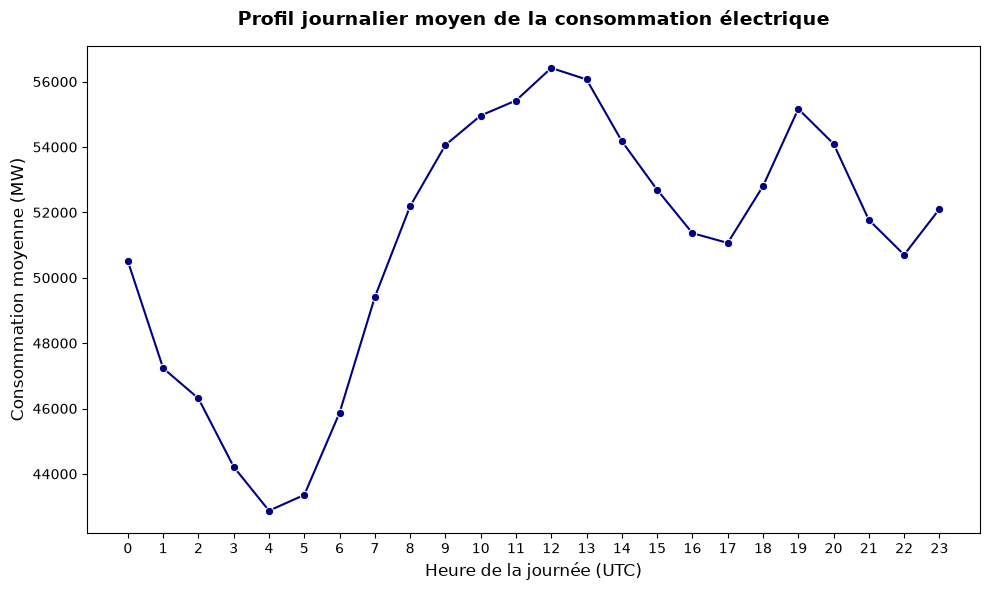

In [16]:
# Étape 1 : Calcul de la consommation moyenne pour chaque heure (de 0 à 23)
conso_moyenne_heure = df_rte_clean.groupby('Heure')['consommation'].mean()

# Étape 2 : Création du graphique avec matplotlib et seaborn
plt.figure(figsize=(10, 6))
sns.lineplot(x=conso_moyenne_heure.index, y=conso_moyenne_heure.values, marker="o", color="navy")

# Étape 3 : Personnalisation esthétique et clarté (critère d'évaluation)
plt.title("Profil journalier moyen de la consommation électrique", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Heure de la journée (UTC)", fontsize=12)
plt.ylabel("Consommation moyenne (MW)", fontsize=12)
plt.xticks(range(0, 24)) # Force l'affichage de chaque heure sur l'axe des abscisses

# Affichage du résultat
plt.tight_layout()
plt.show()

Ce graphique met en évidence la forte saisonnalité durant une journée pour la demande d'électricité. On observe 3 phases distinctes :
1. Le creux nocturne : La consommation atteint son minimum autour de 4h du matin, ainsi lorsque l'activité est au plus bas
2. Le pic de midi : La demande augmente fortement avec le réveil avec ensuite le début de l'activité industrielle et ou tertiaire. On observe alors un premier pic vers 12h.
3. Le pic du soir : Après le pic du midi, on observe une baisse durant l'après-midi. Par la suite on observe un second pic marqué à 19h. Cela correspond au retour des ménages dans leur foyer (Chauffage, Éclairage, Appareils électroménagers).

(L'heure étant en UTC, il ne faut pas oublier que pour trouver l'heure française il faut rajouter respectivement 1h en hiver et 2h en été)